In [4]:
from pathlib import Path

project_root = Path.cwd().parent

print("Repository folder:", project_root)
print("Repository data folder exists:", (project_root / "data").exists())

print("\nSearching for features.txt...")
for path in project_root.parent.rglob("features.txt"):
    print(path)

Repository folder: c:\Users\Harsha\OneDrive\Desktop\ML_capstone\PredictX_Multi_Domain_Predictive_Intelligence
Repository data folder exists: True

Searching for features.txt...
c:\Users\Harsha\OneDrive\Desktop\ML_capstone\data\UCI HAR Dataset\features.txt


In [5]:
DATA_DIR = Path(
    r"C:\Users\Harsha\OneDrive\Desktop\ML_capstone\data\UCI HAR Dataset"
)

In [6]:
print("Dataset folder exists:", DATA_DIR.exists())
print("Features file exists:", (DATA_DIR / "features.txt").exists())
print("Training file exists:", (DATA_DIR / "train" / "X_train.txt").exists())

Dataset folder exists: True
Features file exists: True
Training file exists: True



# Human Activity Recognition Using Clustering

## 1. Introduction

Clustering is an unsupervised machine learning technique that groups similar observations together based on their feature values. Unlike supervised learning, clustering does not require target labels during model training.

## 2. Project Objective

The objective of this project is to apply K-Means and Agglomerative Hierarchical Clustering to the UCI Human Activity Recognition Using Smartphones dataset.

The project aims to:
- Discover patterns in smartphone sensor measurements.
- Identify groups of similar observations.
- Select a suitable number of clusters using the Elbow method.
- Compare clustering algorithms using internal evaluation metrics.
- Visualize clusters using PCA and t-SNE.
- Interpret the clusters using actual activity labels after clustering.

## 3. Dataset

The dataset contains 10,299 observations and 561 engineered features extracted from smartphone accelerometer and gyroscope signals. The six recorded activities are walking, walking upstairs, walking downstairs, sitting, standing, and laying.

Source: UCI Machine Learning Repository.

## 4. Importing Required Libraries

Python libraries are used for data manipulation, numerical computation, visualization, clustering, dimensionality reduction, and evaluation.

- NumPy: numerical operations.
- Pandas: data loading and manipulation.
- Matplotlib and Seaborn: visualization.
- Scikit-learn: preprocessing, clustering, PCA, t-SNE, and evaluation metrics.
- SciPy: hierarchical linkage and dendrogram visualization.



In [7]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme()

print("All libraries imported successfully.")


All libraries imported successfully.



## 5. Dataset Loading

The dataset is divided into training and test sets. Each observation contains 561 numerical features derived from smartphone sensor signals.

For this unsupervised learning project, the feature matrices from both sets are combined. The actual activity labels are loaded separately and are not used to train the clustering algorithms.

This separation prevents the ground-truth labels from influencing cluster formation.


In [8]:

DATA_DIR = Path(
    r"C:\Users\Harsha\OneDrive\Desktop\ML_capstone\data\UCI HAR Dataset"
)

assert (DATA_DIR / "features.txt").exists(), (
    f"Dataset not found at: {DATA_DIR}"
)

# Read feature names
feature_names = pd.read_csv(
    DATA_DIR / "features.txt",
    sep=r"\s+",
    header=None,
    names=["index", "feature"]
)["feature"].tolist()

# Give repeated feature names unique names without removing columns
seen = set()
unique_names = []

for name in feature_names:
    candidate = name
    suffix = 1

    while candidate in seen:
        candidate = f"{name}.{suffix}"
        suffix += 1

    seen.add(candidate)
    unique_names.append(candidate)

feature_names = unique_names

# Load features
X_train = pd.read_csv(
    DATA_DIR / "train" / "X_train.txt",
    sep=r"\s+",
    header=None,
    names=feature_names
)

X_test = pd.read_csv(
    DATA_DIR / "test" / "X_test.txt",
    sep=r"\s+",
    header=None,
    names=feature_names
)

# Load labels separately for later interpretation
y_train = pd.read_csv(
    DATA_DIR / "train" / "y_train.txt",
    sep=r"\s+",
    header=None
).iloc[:, 0]

y_test = pd.read_csv(
    DATA_DIR / "test" / "y_test.txt",
    sep=r"\s+",
    header=None
).iloc[:, 0]

X = pd.concat([X_train, X_test], ignore_index=True)
y_true = pd.concat([y_train, y_test], ignore_index=True)

activity_names = {
    1: "WALKING",
    2: "WALKING_UPSTAIRS",
    3: "WALKING_DOWNSTAIRS",
    4: "SITTING",
    5: "STANDING",
    6: "LAYING"
}

print("Dataset shape:", X.shape)
print("Number of features:", X.shape[1])
print("Missing values:", X.isna().sum().sum())
print("Number of labels:", len(y_true))

display(X.head())


Dataset shape: (10299, 561)
Number of features: 561
Missing values: 0
Number of labels: 10299


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.074323,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,0.158075,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,0.414503,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,0.404573,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,0.087753,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892



## 6. Exploratory Data Analysis (EDA)

Exploratory data analysis is used to understand the dataset before applying machine learning algorithms. It helps identify the number of observations, feature distributions, missing values, and the distribution of recorded activities.

Although actual labels are available, they will only be used for dataset inspection and later interpretation, not as inputs to clustering.


Dataset dimensions: (10299, 561)
Duplicate observations: 0
Missing values: 0


,count,mean,std,min,25%,50%,75%,max
tBodyAcc-mean()-X,10299.0,0.274347,0.067628,-1.0,0.262625,0.277174,0.288354,1.0
tBodyAcc-mean()-Y,10299.0,-0.017743,0.037128,-1.0,-0.024902,-0.017162,-0.010625,1.0
tBodyAcc-mean()-Z,10299.0,-0.108925,0.053033,-1.0,-0.121019,-0.108596,-0.097589,1.0
tBodyAcc-std()-X,10299.0,-0.607784,0.438694,-1.0,-0.992360,-0.943030,-0.250293,1.0
tBodyAcc-std()-Y,10299.0,-0.510191,0.500240,-1.0,-0.976990,-0.835032,-0.057336,1.0
tBodyAcc-std()-Z,10299.0,-0.613064,0.403657,-1.0,-0.979137,-0.850773,-0.278737,1.0
tBodyAcc-mad()-X,10299.0,-0.633593,0.413333,-1.0,-0.993293,-0.948244,-0.302033,1.0
tBodyAcc-mad()-Y,10299.0,-0.525697,0.484201,-1.0,-0.977017,-0.843670,-0.087405,1.0
tBodyAcc-mad()-Z,10299.0,-0.614989,0.399034,-1.0,-0.979064,-0.845068,-0.288149,1.0
tBodyAcc-max()-X,10299.0,-0.466732,0.538707,-1.0,-0.935788,-0.874825,-0.014641,1.0


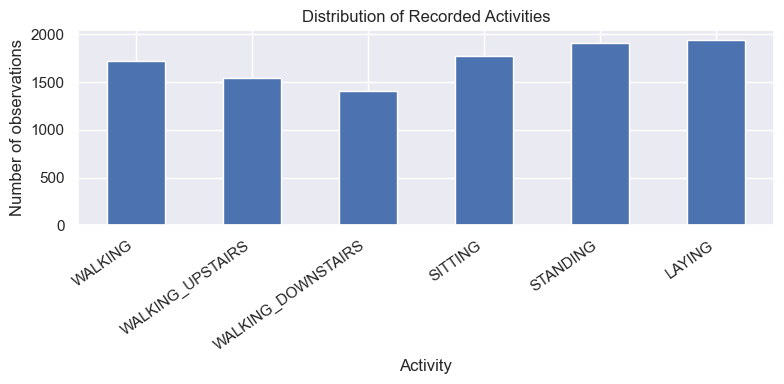

In [9]:

print("Dataset dimensions:", X.shape)
print("Duplicate observations:", X.duplicated().sum())
print("Missing values:", X.isna().sum().sum())

display(X.describe().T.head(10))

activity_counts = (
    y_true.map(activity_names)
    .value_counts()
    .reindex(activity_names.values())
)

activity_counts.plot(kind="bar", figsize=(8, 4))
plt.title("Distribution of Recorded Activities")
plt.xlabel("Activity")
plt.ylabel("Number of observations")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()



## 7. Data Preprocessing and Feature Scaling

Preprocessing prepares numerical data for clustering. Distance-based algorithms can be influenced by differences in feature scales.

Standardization transforms each feature using:

z = (x - μ) / σ

where:
- x is the original feature value.
- μ is the feature mean.
- σ is the feature standard deviation.
- z is the standardized feature value.

The HAR dataset has no missing values according to its official description, but the code checks this before preprocessing. Standardization is applied to all 561 features so that the clustering algorithms can operate on comparable scales.


In [10]:

print("Missing values before preprocessing:", X.isna().sum().sum())

# Standardize the feature matrix
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)
print("Mean of first scaled feature:", round(X_scaled[:, 0].mean(), 4))
print("Standard deviation of first scaled feature:",
      round(X_scaled[:, 0].std(), 4))


Missing values before preprocessing: 0
Scaled data shape: (10299, 561)
Mean of first scaled feature: -0.0
Standard deviation of first scaled feature: 1.0



# 8. K-Means Clustering

K-Means is an unsupervised machine learning algorithm that divides data into K clusters based on similarity. Each observation is assigned to the nearest cluster centroid, and the centroids are updated iteratively until the clusters converge.

The objective is to minimize the Within-Cluster Sum of Squares (WCSS), also called inertia.

## Elbow Method

The Elbow method helps determine a suitable number of clusters (K). It plots the number of clusters against inertia. The best candidate is often near the point where the curve begins to flatten, meaning additional clusters provide less improvement.

## Steps
1. Test different values of K.
2. Calculate inertia for each value.
3. Plot the Elbow curve.
4. Select a suitable K based on the curve.
5. Fit K-Means and examine the cluster sizes.


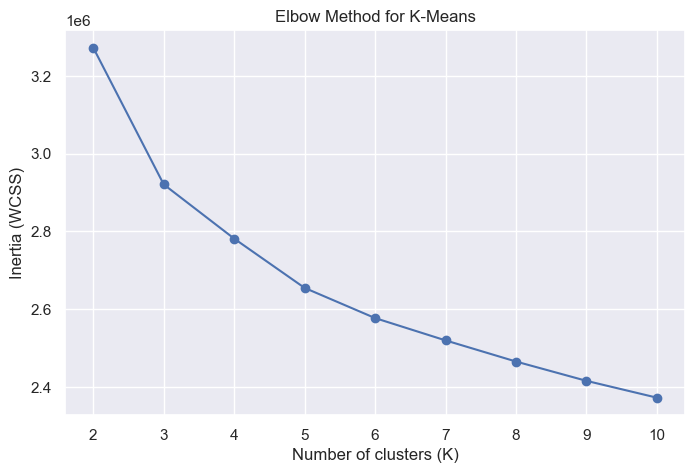

K-Means clustering completed.

Number of observations in each cluster:
0    2638
1     307
2    1920
3    2449
4    1338
5    1647
Name: count, dtype: int64


In [11]:

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans

# Elbow method: test K from 2 to 10
k_values = range(2, 11)
inertias = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    inertias.append(model.inertia_)

# Plot Elbow curve
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia (WCSS)")
plt.title("Elbow Method for K-Means")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

# Fit K-Means with 6 clusters (one for each known activity)
# Change K if the Elbow curve suggests a different value.
kmeans = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed.")
print("\nNumber of observations in each cluster:")
print(pd.Series(kmeans_labels).value_counts().sort_index())



# 9. Agglomerative Hierarchical Clustering

Agglomerative Hierarchical Clustering is an unsupervised learning algorithm that initially treats every observation as an individual cluster. It repeatedly merges the closest clusters until the required number of clusters is reached.

## Linkage Strategies

Different linkage strategies define the distance between clusters differently:

- **Ward:** merges clusters to minimize the increase in within-cluster variance.
- **Complete:** measures the maximum distance between observations in two clusters.
- **Average:** measures the average distance between observations in two clusters.

## Dendrogram

A dendrogram is a tree-like diagram showing how clusters merge at different distances. It helps visualize the hierarchical structure and choose a possible number of clusters.

## Steps
1. Compare Ward, Complete, and Average linkage strategies.
2. Plot a dendrogram to inspect the hierarchy.
3. Fit Agglomerative Clustering with the selected linkage.
4. Compare the resulting cluster sizes and evaluation metrics.

Note: Ward linkage requires Euclidean distance. The dendrogram below uses a sample of observations because a dendrogram containing all 10,299 observations would be very large.


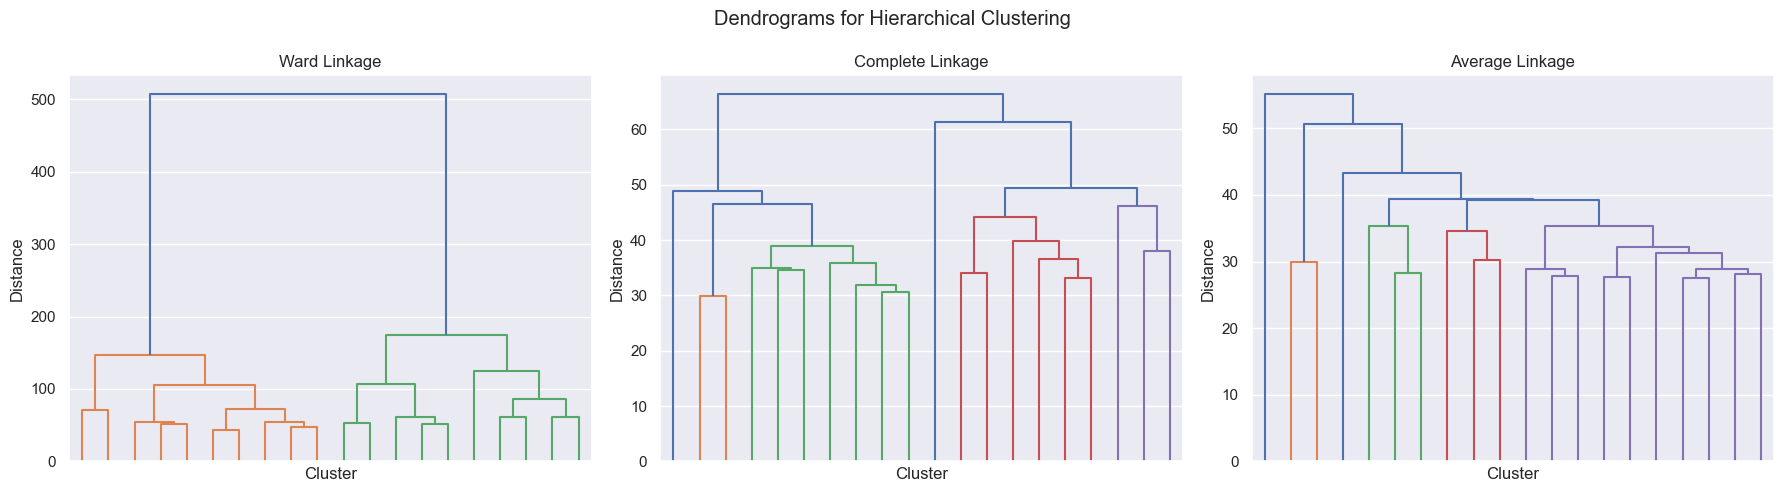


Ward linkage
Cluster sizes:
0    3208
1    1313
2    1206
3    1834
4     151
5    2587
Name: count, dtype: int64

Complete linkage
Cluster sizes:
0    5626
1     218
2       2
3      12
4    4439
5       2
Name: count, dtype: int64


In [ ]:

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram

# Use a sample for a readable dendrogram and reasonable computation time
sample_size = min(500, len(X_scaled))
X_sample = X_scaled[:sample_size]

# Plot dendrograms for the three linkage strategies
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

linkage_methods = ["ward", "complete", "average"]

for ax, method in zip(axes, linkage_methods):
    Z = linkage(X_sample, method=method, metric="euclidean")
    dendrogram(
        Z,
        truncate_mode="lastp",
        p=20,
        ax=ax,
        no_labels=True
    )
    ax.set_title(f"{method.capitalize()} Linkage")
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Distance")

plt.suptitle("Dendrograms for Hierarchical Clustering")
plt.tight_layout()
plt.show()

# Fit and compare all three linkage strategies
hierarchical_labels = {}

for method in linkage_methods:
    model = AgglomerativeClustering(
        n_clusters=6,
        linkage=method
    )
    labels = model.fit_predict(X_scaled)
    hierarchical_labels[method] = labels

    print(f"\n{method.capitalize()} linkage")
    print("Cluster sizes:")
    print(pd.Series(labels).value_counts().sort_index())

print("\nHierarchical clustering completed.")



# 10. Clustering Evaluation Metrics

Clustering evaluation metrics help measure the quality of clusters produced by unsupervised learning algorithms. In this project, K-Means and Agglomerative Hierarchical Clustering are evaluated using three mandatory internal evaluation metrics.

### 1. Silhouette Score
The Silhouette Score measures how similar an observation is to its own cluster compared with other clusters. Its value ranges from -1 to 1. A higher score generally indicates better-separated and more cohesive clusters.

### 2. Davies-Bouldin Index
The Davies-Bouldin Index measures the average similarity between each cluster and its most similar other cluster. A lower score generally indicates better clustering.

### 3. Calinski-Harabasz Index
The Calinski-Harabasz Index compares between-cluster dispersion with within-cluster dispersion. A higher score generally indicates more distinct clusters.

### Evaluation Approach
All three metrics are calculated for K-Means and for each Agglomerative linkage strategy: Ward, Complete, and Average. These metrics use the feature data and predicted cluster assignments, not the ground-truth activity labels.


In [ ]:

import pandas as pd
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Collect cluster labels from all algorithms
all_cluster_labels = {
    "K-Means": kmeans_labels,
    "Agglomerative - Ward": hierarchical_labels["ward"],
    "Agglomerative - Complete": hierarchical_labels["complete"],
    "Agglomerative - Average": hierarchical_labels["average"]
}

# Calculate the three mandatory evaluation metrics
results = []

for algorithm, labels in all_cluster_labels.items():
    # Silhouette score can be computationally expensive on large datasets.
    sil_score = silhouette_score(
        X_scaled,
        labels,
        sample_size=min(3000, len(X_scaled)),
        random_state=42
    )

    db_index = davies_bouldin_score(X_scaled, labels)
    ch_index = calinski_harabasz_score(X_scaled, labels)

    results.append({
        "Algorithm": algorithm,
        "Silhouette Score (higher is better)": sil_score,
        "Davies-Bouldin Index (lower is better)": db_index,
        "Calinski-Harabasz Index (higher is better)": ch_index
    })

metrics_df = pd.DataFrame(results)

print("Clustering Evaluation Results")
display(metrics_df.round(4))


Clustering Evaluation Results


,Algorithm,Silhouette Score (higher is better),Davies-Bouldin Index (lower is better),Calinski-Harabasz Index (higher is better)
0,K-Means,0.1096,2.3836,2556.5419
1,Agglomerative - Ward,0.1139,2.4820,2349.6677
2,Agglomerative - Complete,0.3804,1.3004,1898.4100
3,Agglomerative - Average,0.4287,1.1020,161.1037


In [ ]:
all_cluster_labels = {
    "K-Means": kmeans_labels,
    "Agglomerative - Ward": hierarchical_labels["ward"],
    "Agglomerative - Complete": hierarchical_labels["complete"],
    "Agglomerative - Average": hierarchical_labels["average"]
}

NameError: name 'kmeans_labels' is not defined


# 11. Cluster Visualization Using PCA

Principal Component Analysis (PCA) is a dimensionality reduction technique that transforms high-dimensional data into a smaller number of principal components while preserving as much variance as possible.

The Human Activity Recognition dataset contains 561 features. PCA reduces these features to two principal components so that the clustering results can be visualized in a two-dimensional plot.

### Objectives
- Visualize clusters produced by K-Means.
- Compare clusters produced by Ward, Complete, and Average hierarchical linkage.
- Observe the separation and overlap between clusters.

Each point represents an observation, and its color represents the cluster assigned by the algorithm. PCA is used only for visualization; clustering was performed using the scaled original features.


Original feature count: 561
PCA feature count: 2
Total variance explained: 56.98 %


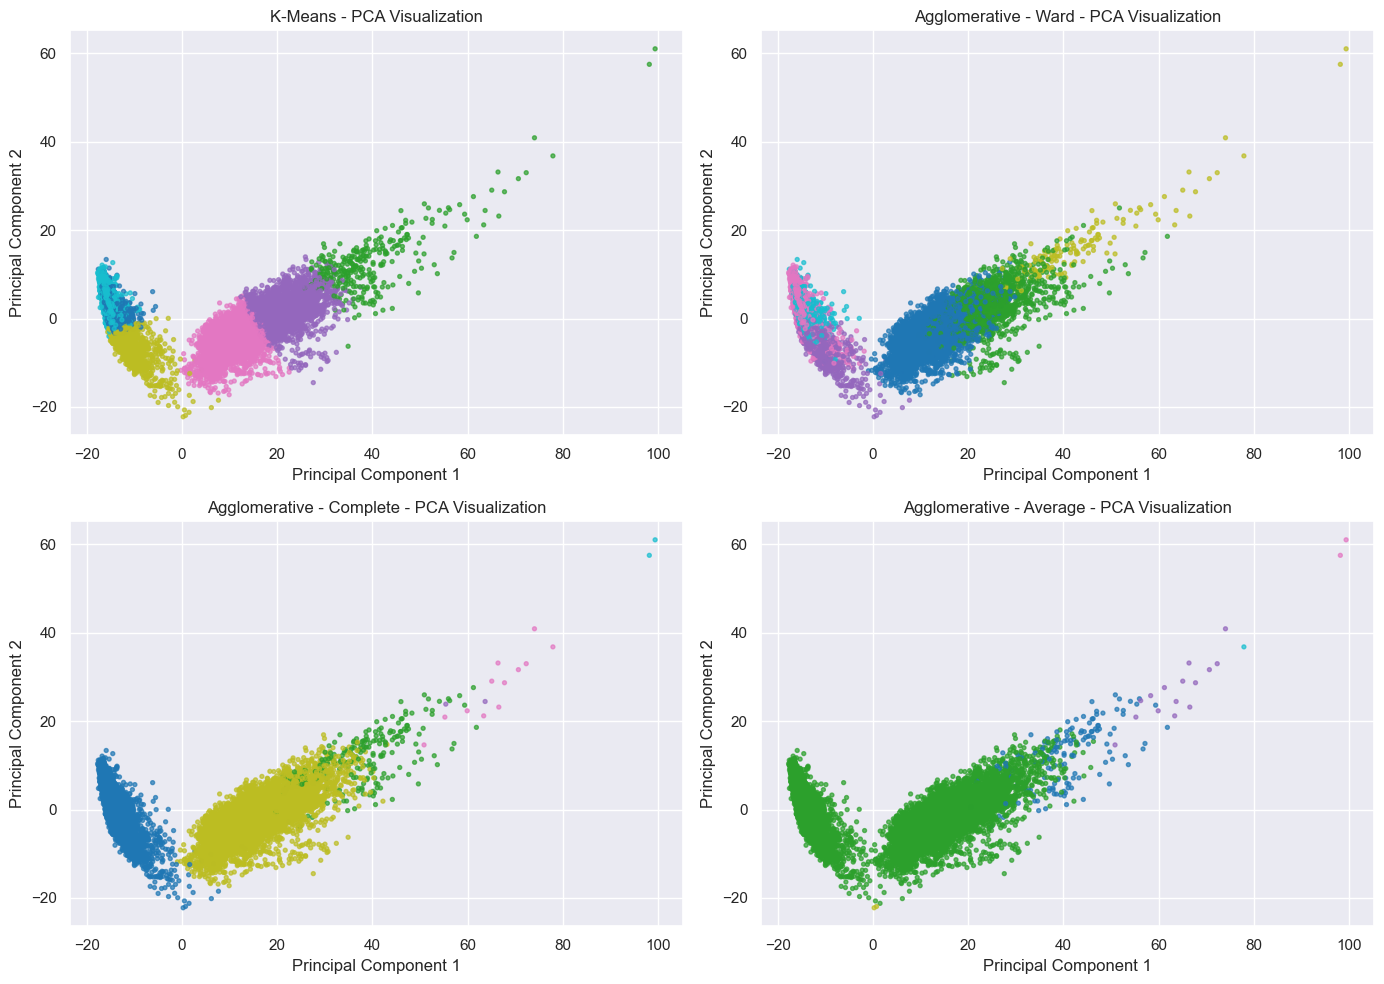

In [ ]:

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Reduce the scaled data to two principal components
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print("Original feature count:", X_scaled.shape[1])
print("PCA feature count:", X_pca.shape[1])
print(
    "Total variance explained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

# Visualize every clustering algorithm
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for ax, (algorithm, labels) in zip(
    axes, all_cluster_labels.items()
):
    scatter = ax.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=labels,
        cmap="tab10",
        s=8,
        alpha=0.7
    )

    ax.set_title(f"{algorithm} - PCA Visualization")
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()



# 12. Cluster Visualization Using t-SNE

t-Distributed Stochastic Neighbor Embedding (t-SNE) is a nonlinear dimensionality reduction technique that maps high-dimensional data into a lower-dimensional space while attempting to preserve local similarities between observations.

In this project, t-SNE is used to visualize clustering results in two dimensions.

### Objectives
- Examine local grouping patterns in the dataset.
- Visualize clusters generated by K-Means.
- Compare the visual patterns with the PCA visualization.

Because t-SNE can be computationally expensive, a reproducible sample of observations is used. The existing cluster assignments are displayed; t-SNE does not train or change the clustering algorithms.

Note: Distances between widely separated groups in a t-SNE plot should not be interpreted as reliable measures of global separation.


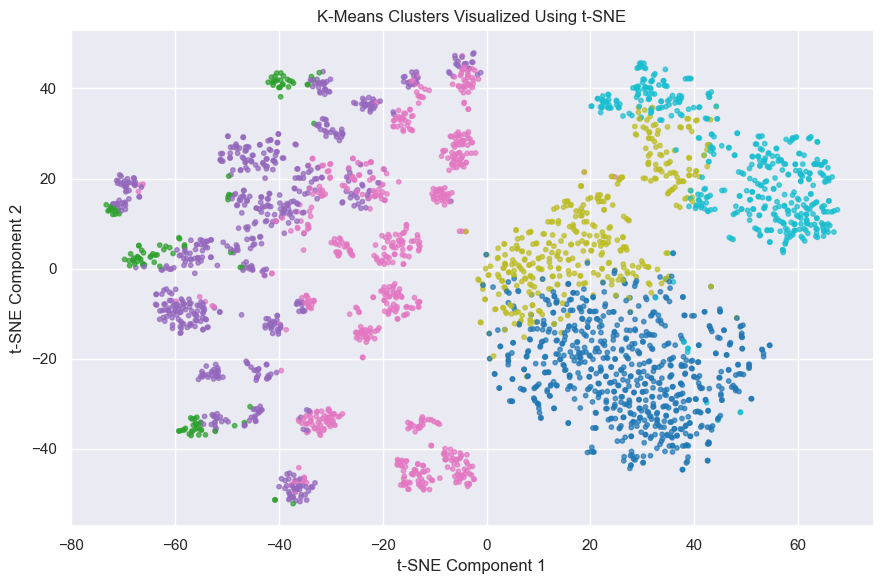

In [ ]:

import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

# Use a reproducible sample to reduce computation time
sample_size = min(3000, len(X_scaled))

# Select the same observations for features and cluster labels
sample_indices = range(sample_size)
X_tsne_input = X_scaled[sample_indices]
sample_labels = kmeans_labels[sample_indices]

# Compute the two-dimensional t-SNE embedding
tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=42
)

X_tsne = tsne.fit_transform(X_tsne_input)

# Visualize K-Means clusters
plt.figure(figsize=(9, 6))
plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=sample_labels,
    cmap="tab10",
    s=10,
    alpha=0.7
)

plt.title("K-Means Clusters Visualized Using t-SNE")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.tight_layout()
plt.show()
